<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/sessions/Session11_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۱۱: خوشه‌بندی (Clustering)

### اهداف این جلسه

- آشنایی با یادگیری بدون نظارت و کاربردهای خوشه‌بندی
- الگوریتم **K-Means**: پیاده‌سازی از صفر، K-Means++ و انتخاب تعداد خوشه‌ها
- معیارهای ارزیابی خوشه‌بندی: Inertia، **Silhouette** و ARI
- پروژهٔ عملی: **بخش‌بندی مشتریان** یک مرکز خرید
- خوشه‌بندی سلسله‌مراتبی و دندروگرام
- **DBSCAN** برای خوشه‌های با شکل دلخواه و تشخیص نویز
- **مدل مخلوط گوسی (GMM)** و پیاده‌سازی الگوریتم **EM** از صفر

## ۱. یادگیری بدون نظارت و خوشه‌بندی

در یادگیری بدون نظارت، **برچسب نداریم**. هدف خوشه‌بندی، گروه‌بندی نمونه‌ها به‌طوری است که نمونه‌های هر گروه به هم **شبیه** و به نمونه‌های گروه‌های دیگر **متفاوت** باشند.

کاربردها:
- **بخش‌بندی مشتریان** برای بازاریابی هدفمند
- **فشرده‌سازی تصویر** با کاهش تعداد رنگ‌ها
- **تشخیص ناهنجاری**: نمونه‌هایی که به هیچ خوشه‌ای تعلق ندارند
- **پیش‌پردازش**: استفاده از شمارهٔ خوشه به‌عنوان ویژگی جدید
- گروه‌بندی اسناد، ژن‌ها یا تصاویر مشابه

چالش اصلی: چون جواب درستی وجود ندارد، **ارزیابی** خوشه‌بندی سخت است و تفسیر انسانی نقش مهمی دارد.

## ۲. الگوریتم K-Means

K-Means داده را به $K$ خوشه تقسیم می‌کند و هر خوشه با **مرکزش (centroid)** نمایش داده می‌شود:

1. $K$ مرکز اولیه انتخاب کن.
2. **گام تخصیص:** هر نمونه را به نزدیک‌ترین مرکز اختصاص بده.
3. **گام به‌روزرسانی:** هر مرکز را به میانگین نمونه‌های خوشه‌اش منتقل کن.
4. گام‌های ۲ و ۳ را تا وقتی مراکز تغییر نکنند تکرار کن.

K-Means در واقع مجموع مربع فاصلهٔ نمونه‌ها تا مرکز خوشه‌شان را کمینه می‌کند که به آن **Inertia** یا WCSS می‌گویند:

$$J = \sum_{k=1}^{K} \sum_{\mathbf{x} \in C_k} \left\| \mathbf{x} - \boldsymbol{\mu}_k \right\|^2$$

### ۲.۱ پیاده‌سازی از صفر

</div>

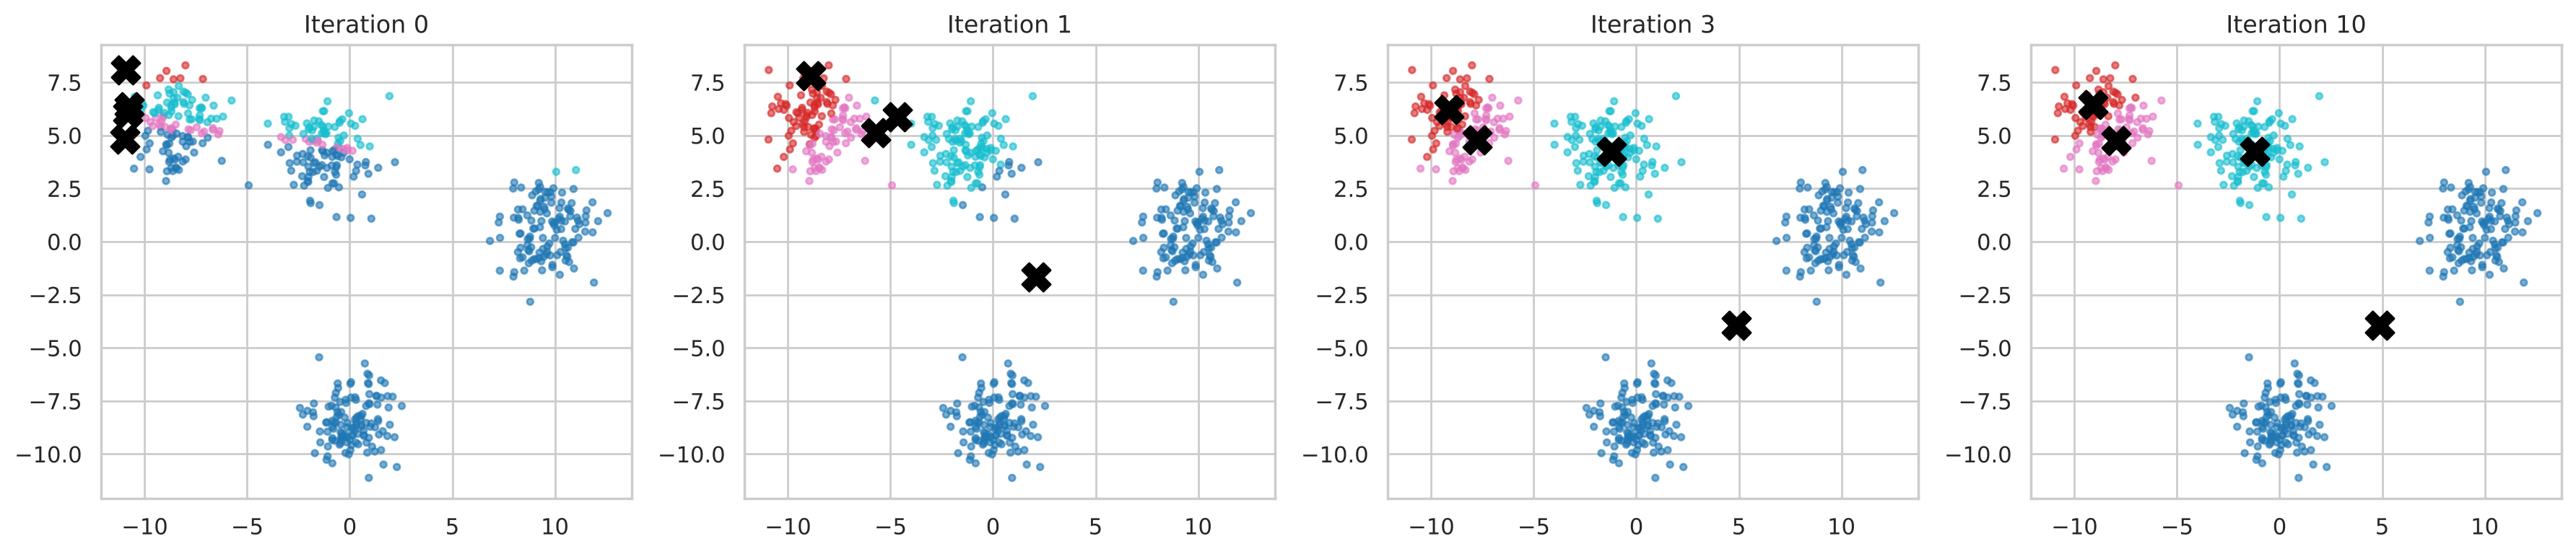

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs

sns.set_theme(style="whitegrid")

X, y_true = make_blobs(n_samples=500, centers=4, cluster_std=1.2, random_state=7)

def kmeans_from_scratch(X, k, n_iter=10, initial_centroids=None, seed=0):
    rng = np.random.default_rng(seed)
    centroids = X[rng.choice(len(X), k, replace=False)] if initial_centroids is None else initial_centroids
    history = [centroids.copy()]
    for _ in range(n_iter):
        distances = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
        labels = distances.argmin(axis=1)
        centroids = np.array([X[labels == j].mean(axis=0) for j in range(k)])
        history.append(centroids.copy())
    return labels, centroids, history

# deliberately poor start: the four left-most points, to make the movement visible
bad_start = X[np.argsort(X[:, 0])[:4]]
labels, centroids, history = kmeans_from_scratch(X, k=4, initial_centroids=bad_start)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, step in zip(axes, [0, 1, 3, 10]):
    c = history[step]
    step_labels = np.linalg.norm(X[:, None] - c[None], axis=2).argmin(axis=1)
    ax.scatter(X[:, 0], X[:, 1], c=step_labels, cmap="tab10", s=10, alpha=0.6)
    ax.scatter(c[:, 0], c[:, 1], c="black", marker="X", s=200)
    ax.set_title(f"Iteration {step}")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

برای اینکه حرکت مراکز دیده شود، عمداً چهار نقطهٔ سمت چپ را به‌عنوان مراکز اولیه انتخاب کرده‌ایم. مراکز (ضربدرهای سیاه) در هر تکرار جابه‌جا می‌شوند و بعد از چند تکرار ثابت می‌مانند؛ الگوریتم **همگرا** شده است.

ولی به نتیجهٔ نهایی دقت کنید: دو مرکز در خوشهٔ بالا-چپ گیر کرده‌اند و یک مرکز بین دو خوشهٔ پایین و راست قرار گرفته است. الگوریتم همگرا شده، ولی جواب **غلط** است! این همان مشکل کمینهٔ محلی است.

### ۲.۲ مشکل مقداردهی اولیه و K-Means++

K-Means فقط تضمین می‌کند به یک **کمینهٔ محلی** برسد، نه لزوماً بهترین جواب؛ همان چیزی که بالا دیدیم. دو راه‌حل که scikit-learn به‌طور پیش‌فرض از هر دو استفاده می‌کند:
- **K-Means++:** مراکز اولیه را طوری انتخاب می‌کند که از هم دور باشند.
- **`n_init`:** الگوریتم را چند بار با شروع‌های مختلف اجرا می‌کند و جوابی را با کمترین Inertia برمی‌گزیند.

</div>

In [2]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
print("Inertia:", round(kmeans.inertia_, 1))
print("Cluster sizes:", np.bincount(kmeans.labels_))

Inertia: 1324.7
Cluster sizes: [125 125 125 125]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۳. انتخاب تعداد خوشه‌ها

### ۳.۱ روش آرنج (Elbow)

Inertia با افزایش $K$ همیشه کم می‌شود (با $K = m$ صفر می‌شود!). پس نمی‌توان $K$ را با کمینه کردن Inertia انتخاب کرد. در روش آرنج، دنبال نقطه‌ای می‌گردیم که بعد از آن، کاهش Inertia ناگهان کند می‌شود.

### ۳.۲ ضریب Silhouette

برای هر نمونه $i$:
- $a(i)$: میانگین فاصله تا بقیهٔ نمونه‌های **همان خوشه**
- $b(i)$: میانگین فاصله تا نمونه‌های **نزدیک‌ترین خوشهٔ دیگر**

$$s(i) = \frac{b(i) - a(i)}{\max\left(a(i), b(i)\right)}$$

مقدار $s$ بین $-1$ و $+1$ است: نزدیک $+1$ یعنی نمونه به‌خوبی در خوشهٔ خودش قرار دارد، نزدیک صفر یعنی روی مرز دو خوشه است و منفی یعنی احتمالاً در خوشهٔ اشتباه است. میانگین $s$ روی همهٔ نمونه‌ها، کیفیت کل خوشه‌بندی را نشان می‌دهد.

</div>

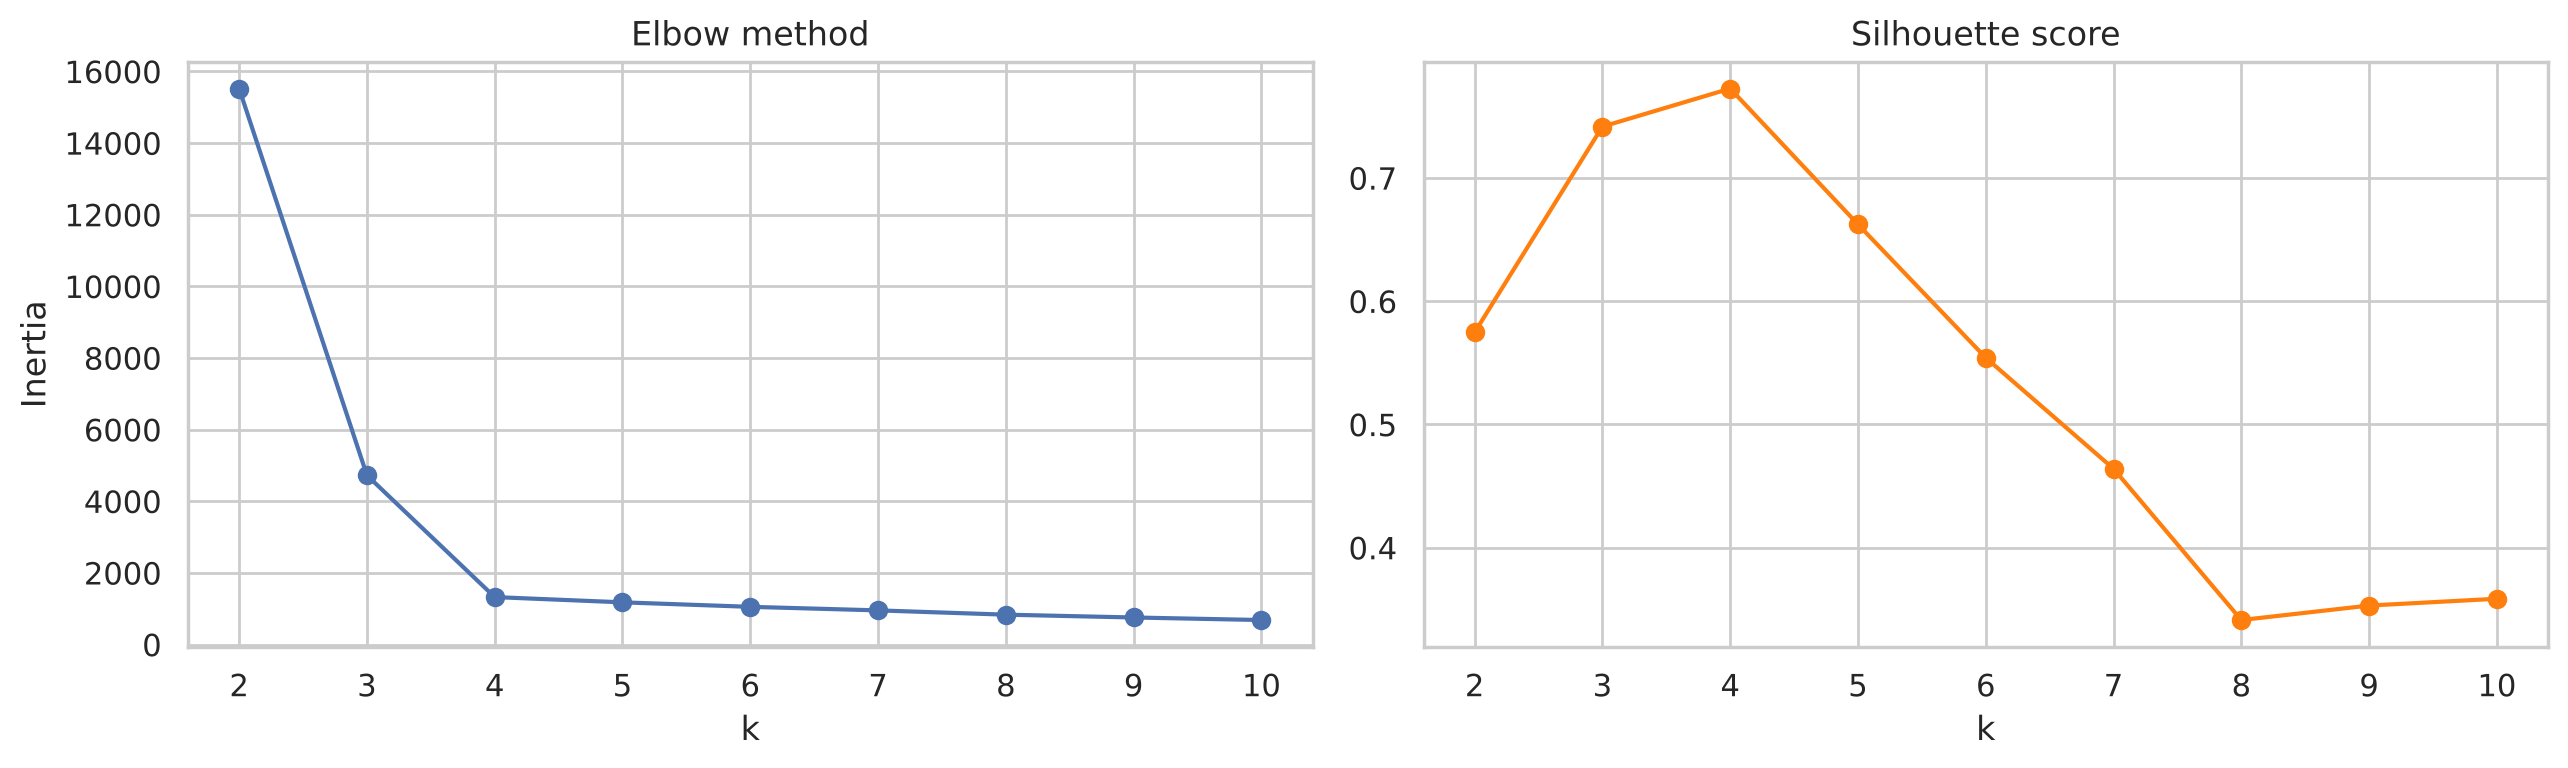

In [3]:
from sklearn.metrics import silhouette_score

ks = range(2, 11)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ks, inertias, "o-")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[1].plot(ks, silhouettes, "o-", color="tab:orange")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

هر دو روش $K=4$ را پیشنهاد می‌کنند که با تعداد واقعی خوشه‌ها برابر است. در دادهٔ واقعی، جواب به این روشنی نیست و این معیارها فقط **راهنما** هستند؛ دانش حوزه و هدف کسب‌وکار هم در انتخاب $K$ نقش دارند.

## ۴. پروژه: بخش‌بندی مشتریان مرکز خرید

داده شامل ۲۰۰ مشتری یک مرکز خرید است: جنسیت، سن، درآمد سالانه (هزار دلار) و **امتیاز خرید** (۱ تا ۱۰۰) که مرکز خرید بر اساس رفتار خرید هر مشتری به او داده است. هدف: پیدا کردن گروه‌های مشتری برای بازاریابی هدفمند.

</div>

In [4]:
DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"
mall = pd.read_csv(DATA_URL + "Mall_Customers.csv")
mall = mall.rename(columns={"Genre": "Gender", "Annual Income (k$)": "Income", "Spending Score (1-100)": "Spending"})
mall.head()

,CustomerID,Gender,Age,Income,Spending
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


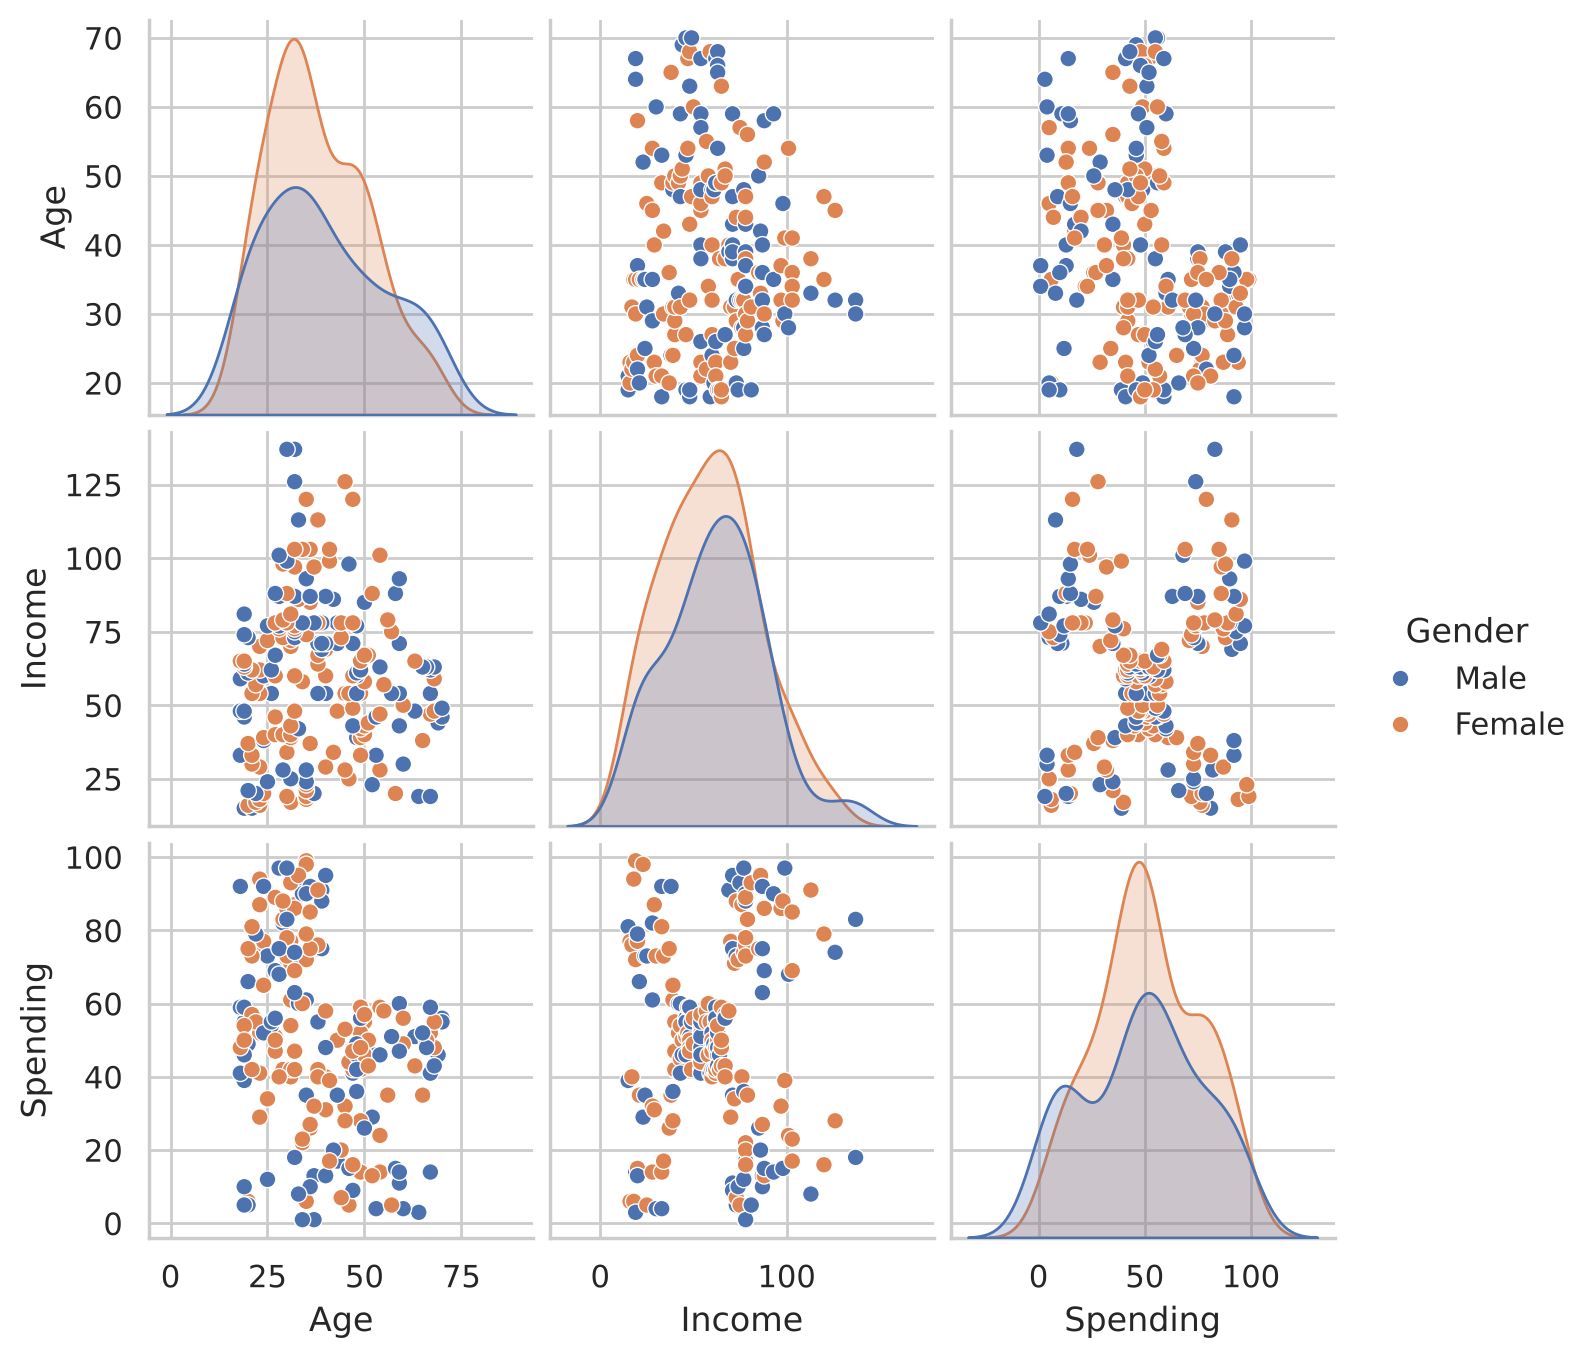

In [5]:
sns.pairplot(mall.drop(columns="CustomerID"), hue="Gender", height=2.3)
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در نمودار درآمد در برابر امتیاز خرید، چند گروه کاملاً قابل تشخیص‌اند. ابتدا روی همین دو ویژگی خوشه‌بندی می‌کنیم تا نتیجه قابل رسم باشد. چون K-Means بر پایهٔ فاصله است، **مقیاس‌بندی** لازم است.

</div>

In [6]:
from sklearn.preprocessing import StandardScaler

features = ["Income", "Spending"]
X_mall = StandardScaler().fit_transform(mall[features])

scores = {k: silhouette_score(X_mall, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_mall))
          for k in range(2, 11)}
print({k: round(v, 3) for k, v in scores.items()})
best_k = max(scores, key=scores.get)
print("Best k by silhouette:", best_k)

{2: 0.321, 3: 0.467, 4: 0.494, 5: 0.555, 6: 0.54, 7: 0.528, 8: 0.455, 9: 0.457, 10: 0.443}
Best k by silhouette: 5


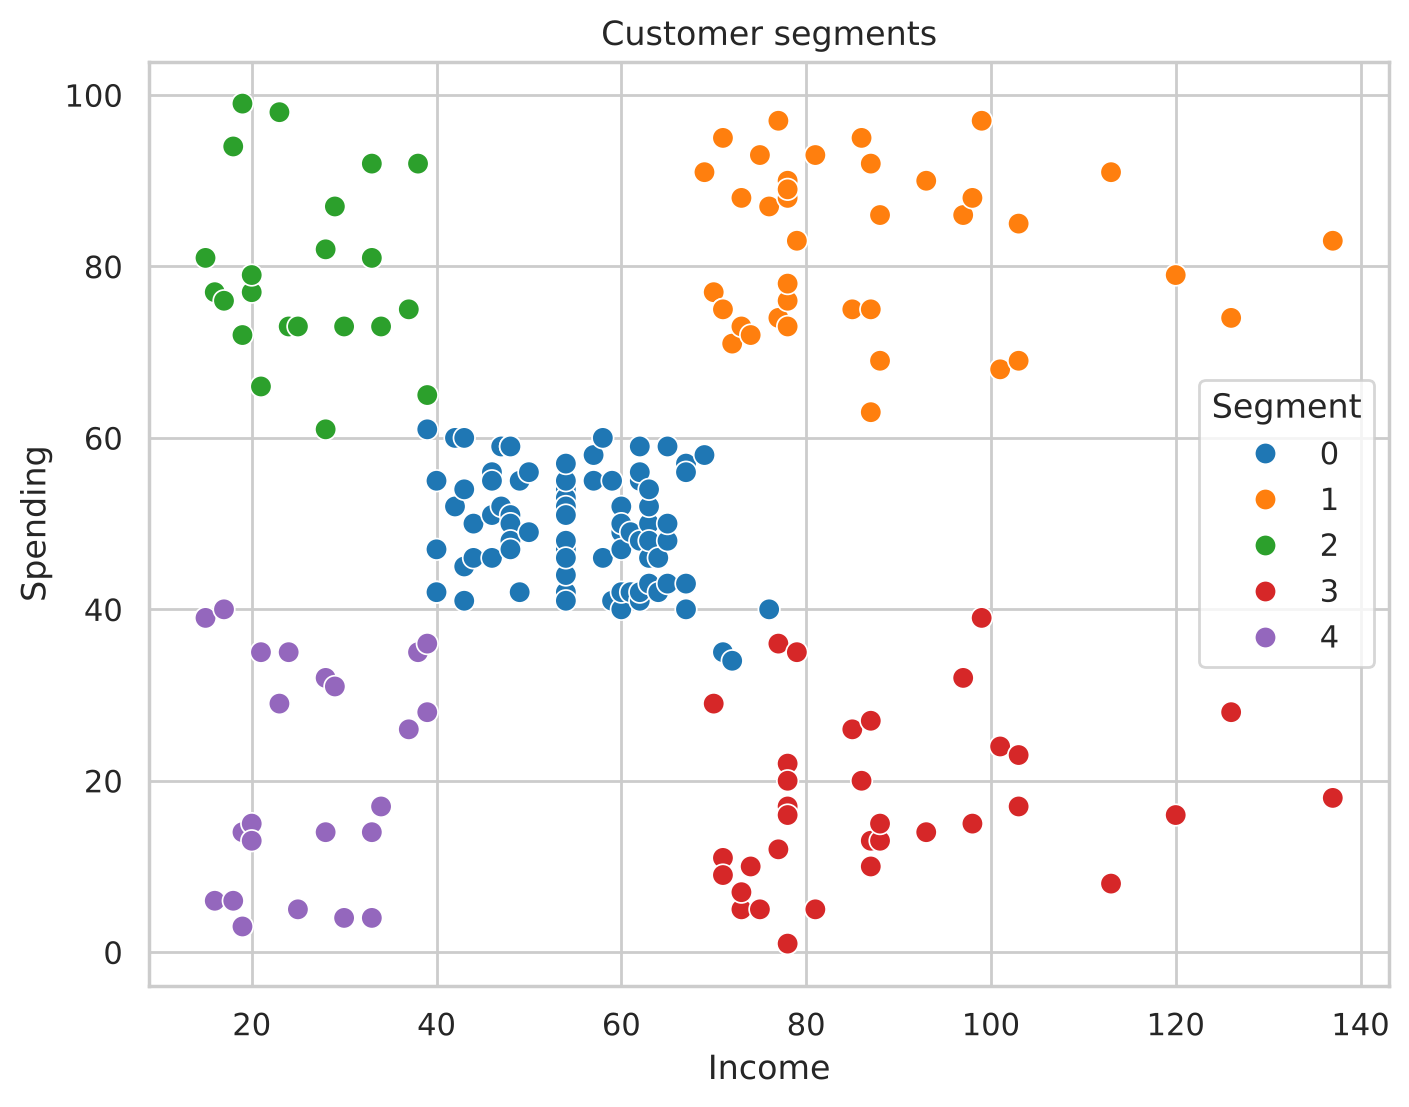

,Age,Income,Spending,Count
Segment,,,,
0,42.7,55.3,49.5,81
1,32.7,86.5,82.1,39
2,25.3,25.7,79.4,22
3,41.1,88.2,17.1,35
4,45.2,26.3,20.9,23


In [7]:
km_mall = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(X_mall)
mall["Segment"] = km_mall.labels_

plt.figure(figsize=(8, 6))
sns.scatterplot(data=mall, x="Income", y="Spending", hue="Segment", palette="tab10", s=60)
plt.title("Customer segments")
plt.show()

mall.groupby("Segment")[["Age", "Income", "Spending"]].mean().round(1).assign(
    Count=mall["Segment"].value_counts().sort_index())

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

حالا باید هر بخش را **تفسیر** کنیم؛ این مهم‌ترین قسمت کار است. با نگاه به میانگین‌ها، معمولاً این پنج گروه دیده می‌شوند:

- **درآمد بالا، خرید بالا:** مشتریان هدف اصلی؛ برنامه‌های وفاداری و محصولات ویژه
- **درآمد بالا، خرید پایین:** پتانسیل رشد؛ باید فهمید چرا کم خرید می‌کنند
- **درآمد متوسط، خرید متوسط:** بزرگ‌ترین گروه؛ مشتریان عادی
- **درآمد پایین، خرید بالا:** معمولاً جوان‌تر؛ حساس به تخفیف
- **درآمد پایین، خرید پایین:** محتاط

(شمارهٔ هر بخش دلخواه است و با اجرای مجدد ممکن است عوض شود؛ برای شناسایی هر گروه، به میانگین‌های جدول نگاه کنید.)

## ۵. محدودیت‌های K-Means

K-Means فرض می‌کند خوشه‌ها **کروی**، با **اندازهٔ مشابه** و **چگالی مشابه** هستند، چون هر نقطه را به نزدیک‌ترین مرکز می‌دهد. وقتی این فرض‌ها برقرار نیستند، شکست می‌خورد:

</div>

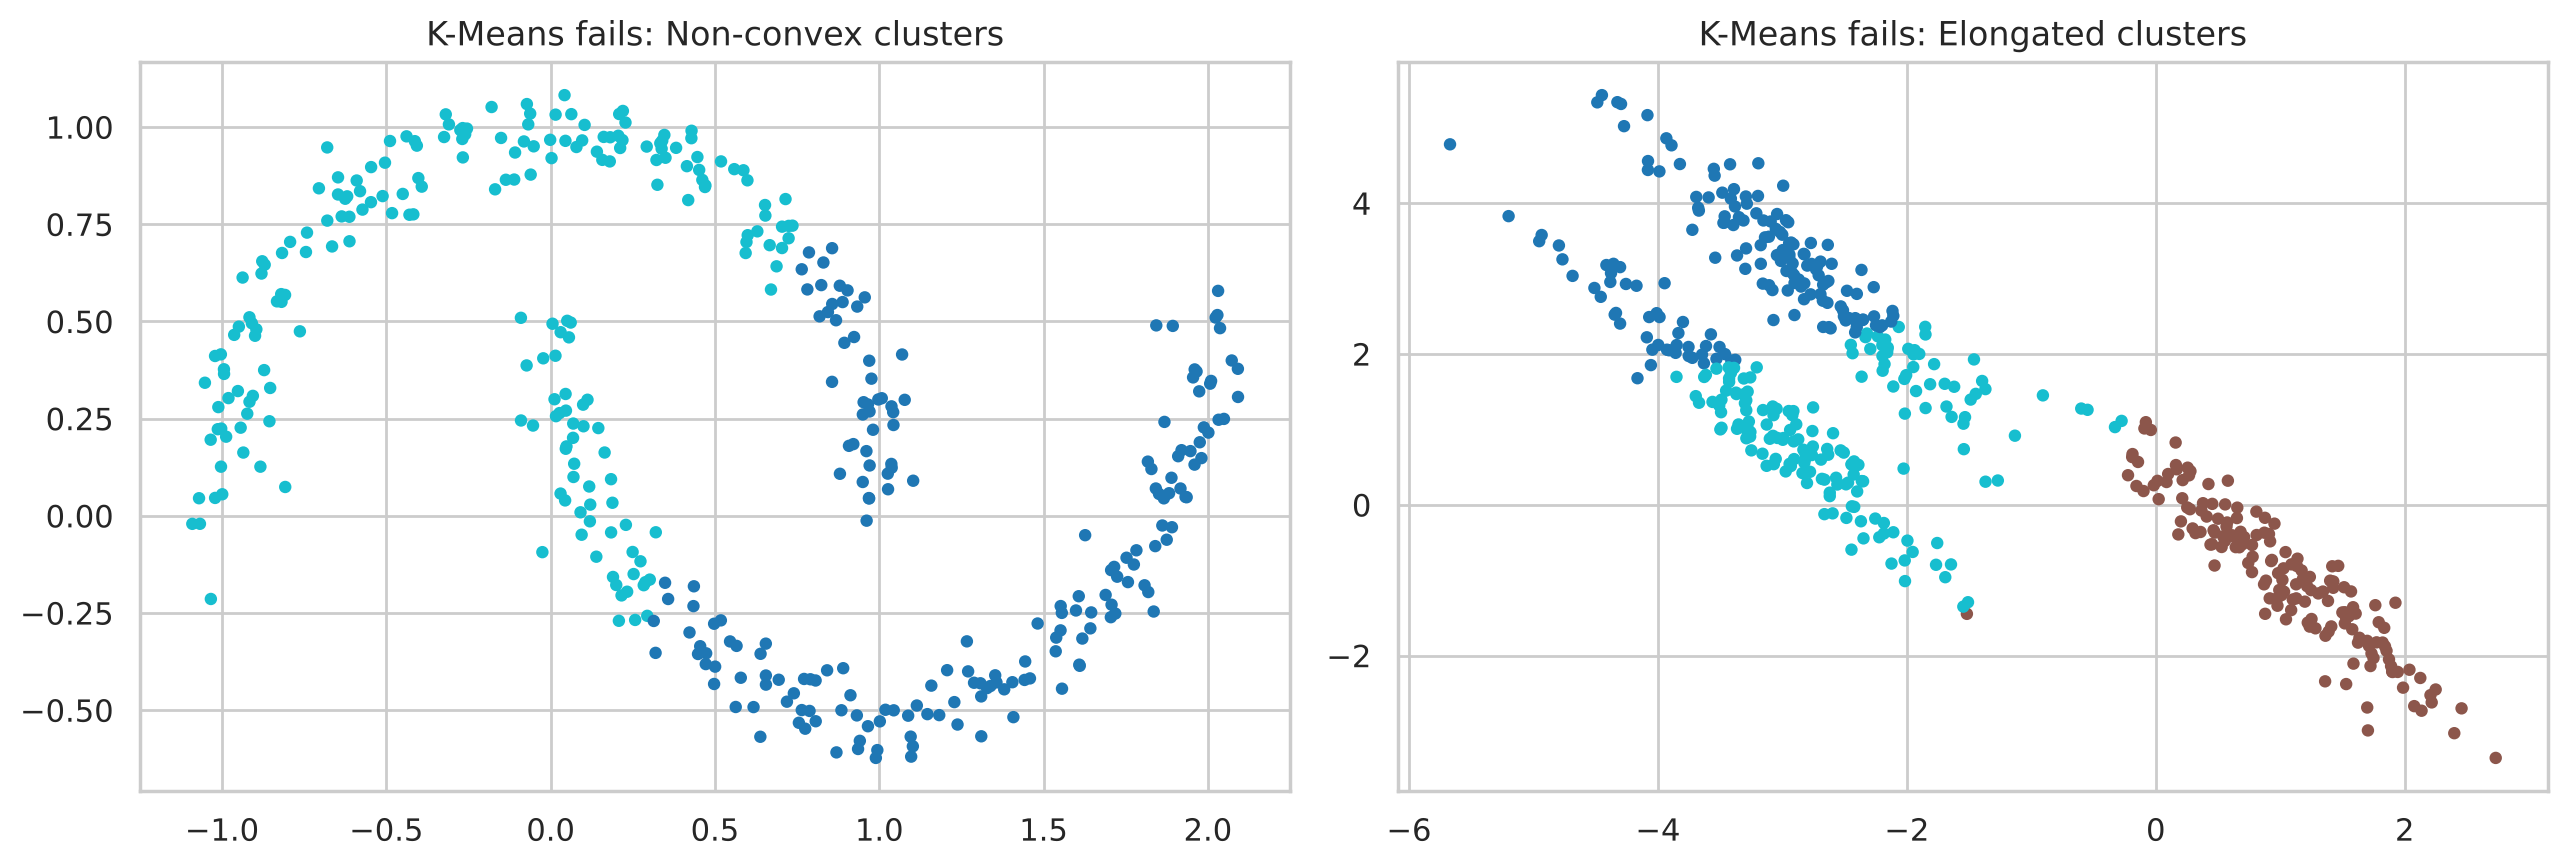

In [8]:
from sklearn.datasets import make_moons

X_moons, _ = make_moons(n_samples=400, noise=0.06, random_state=42)
rng = np.random.default_rng(0)
X_aniso = make_blobs(n_samples=500, centers=3, random_state=170)[0] @ np.array([[0.6, -0.64], [-0.41, 0.85]])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, data, title in [(axes[0], X_moons, "Non-convex clusters"), (axes[1], X_aniso, "Elongated clusters")]:
    labels = KMeans(n_clusters=2 if data is X_moons else 3, n_init=10, random_state=42).fit_predict(data)
    ax.scatter(data[:, 0], data[:, 1], c=labels, cmap="tab10", s=12)
    ax.set_title(f"K-Means fails: {title}")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

برای این موارد سراغ الگوریتم‌های دیگر می‌رویم.

## ۶. خوشه‌بندی سلسله‌مراتبی (Hierarchical)

**خوشه‌بندی تجمعی (Agglomerative)** از پایین به بالا کار می‌کند:
1. هر نمونه را یک خوشهٔ جداگانه در نظر بگیر.
2. در هر مرحله، دو خوشهٔ **نزدیک‌تر** را ادغام کن.
3. تا وقتی یک خوشه باقی بماند تکرار کن.

نتیجه یک درخت به نام **دندروگرام** است. با بریدن درخت در یک ارتفاع مشخص، تعداد خوشه‌ها تعیین می‌شود؛ لازم نیست $K$ را از قبل بدانیم.

**معیار پیوند (Linkage)** تعیین می‌کند فاصلهٔ دو خوشه چطور حساب شود:

| پیوند | فاصلهٔ دو خوشه | ویژگی |
|---|---|---|
| `single` | نزدیک‌ترین جفت نقطه | خوشه‌های زنجیره‌ای و کشیده |
| `complete` | دورترین جفت نقطه | خوشه‌های فشرده |
| `average` | میانگین فاصلهٔ همهٔ جفت‌ها | حالت میانه |
| `ward` | افزایش واریانس درون‌خوشه‌ای پس از ادغام | شبیه K-Means؛ پیش‌فرض |

</div>

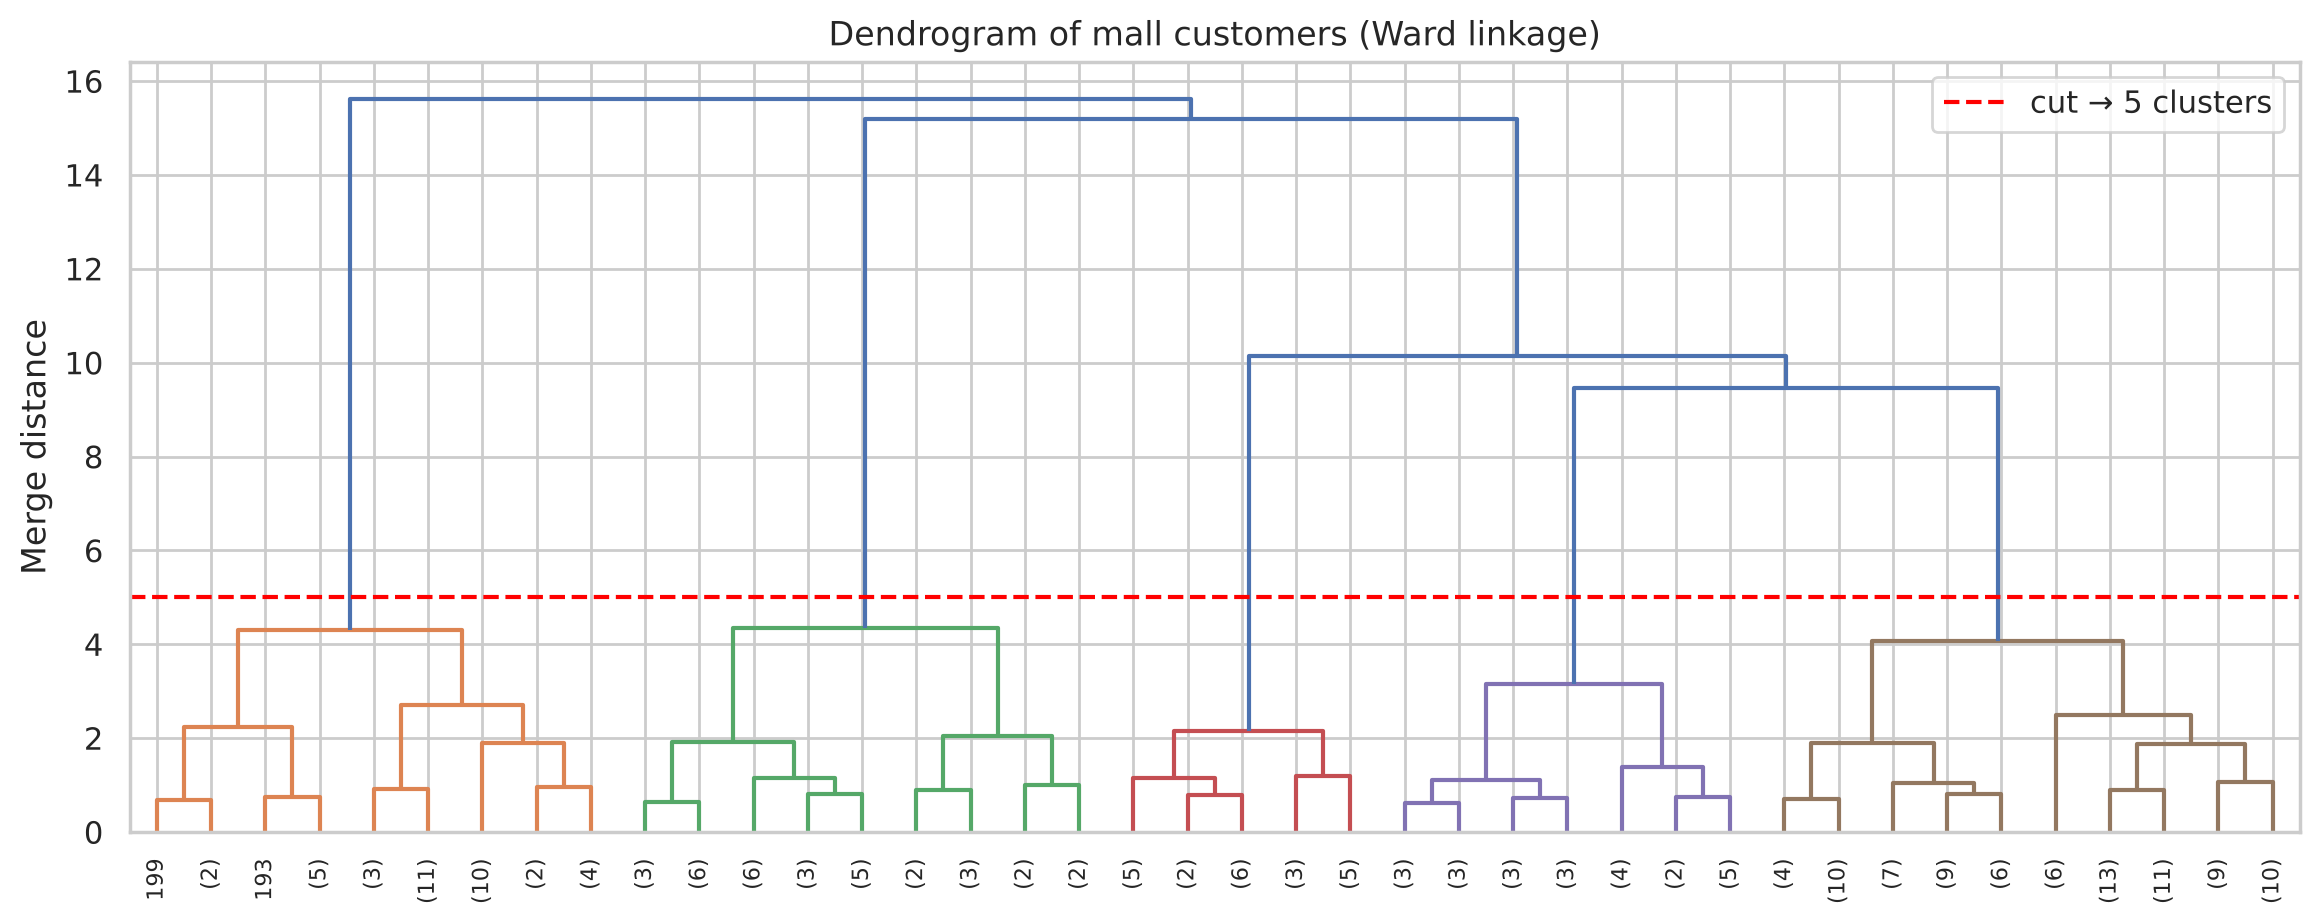

In [9]:
from scipy.cluster.hierarchy import dendrogram, linkage

Z = linkage(X_mall, method="ward")
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode="lastp", p=40, leaf_rotation=90, color_threshold=5)
plt.axhline(5, color="red", linestyle="--", label="cut → 5 clusters")
plt.title("Dendrogram of mall customers (Ward linkage)")
plt.ylabel("Merge distance")
plt.legend()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

فاصله‌های عمودی بلند در دندروگرام یعنی دو خوشهٔ بسیار متفاوت ادغام شده‌اند. بریدن درخت بالای بلندترین شاخه‌ها، تعداد طبیعی خوشه‌ها را نشان می‌دهد. اینجا هم ۵ خوشه پیشنهاد می‌شود.

</div>

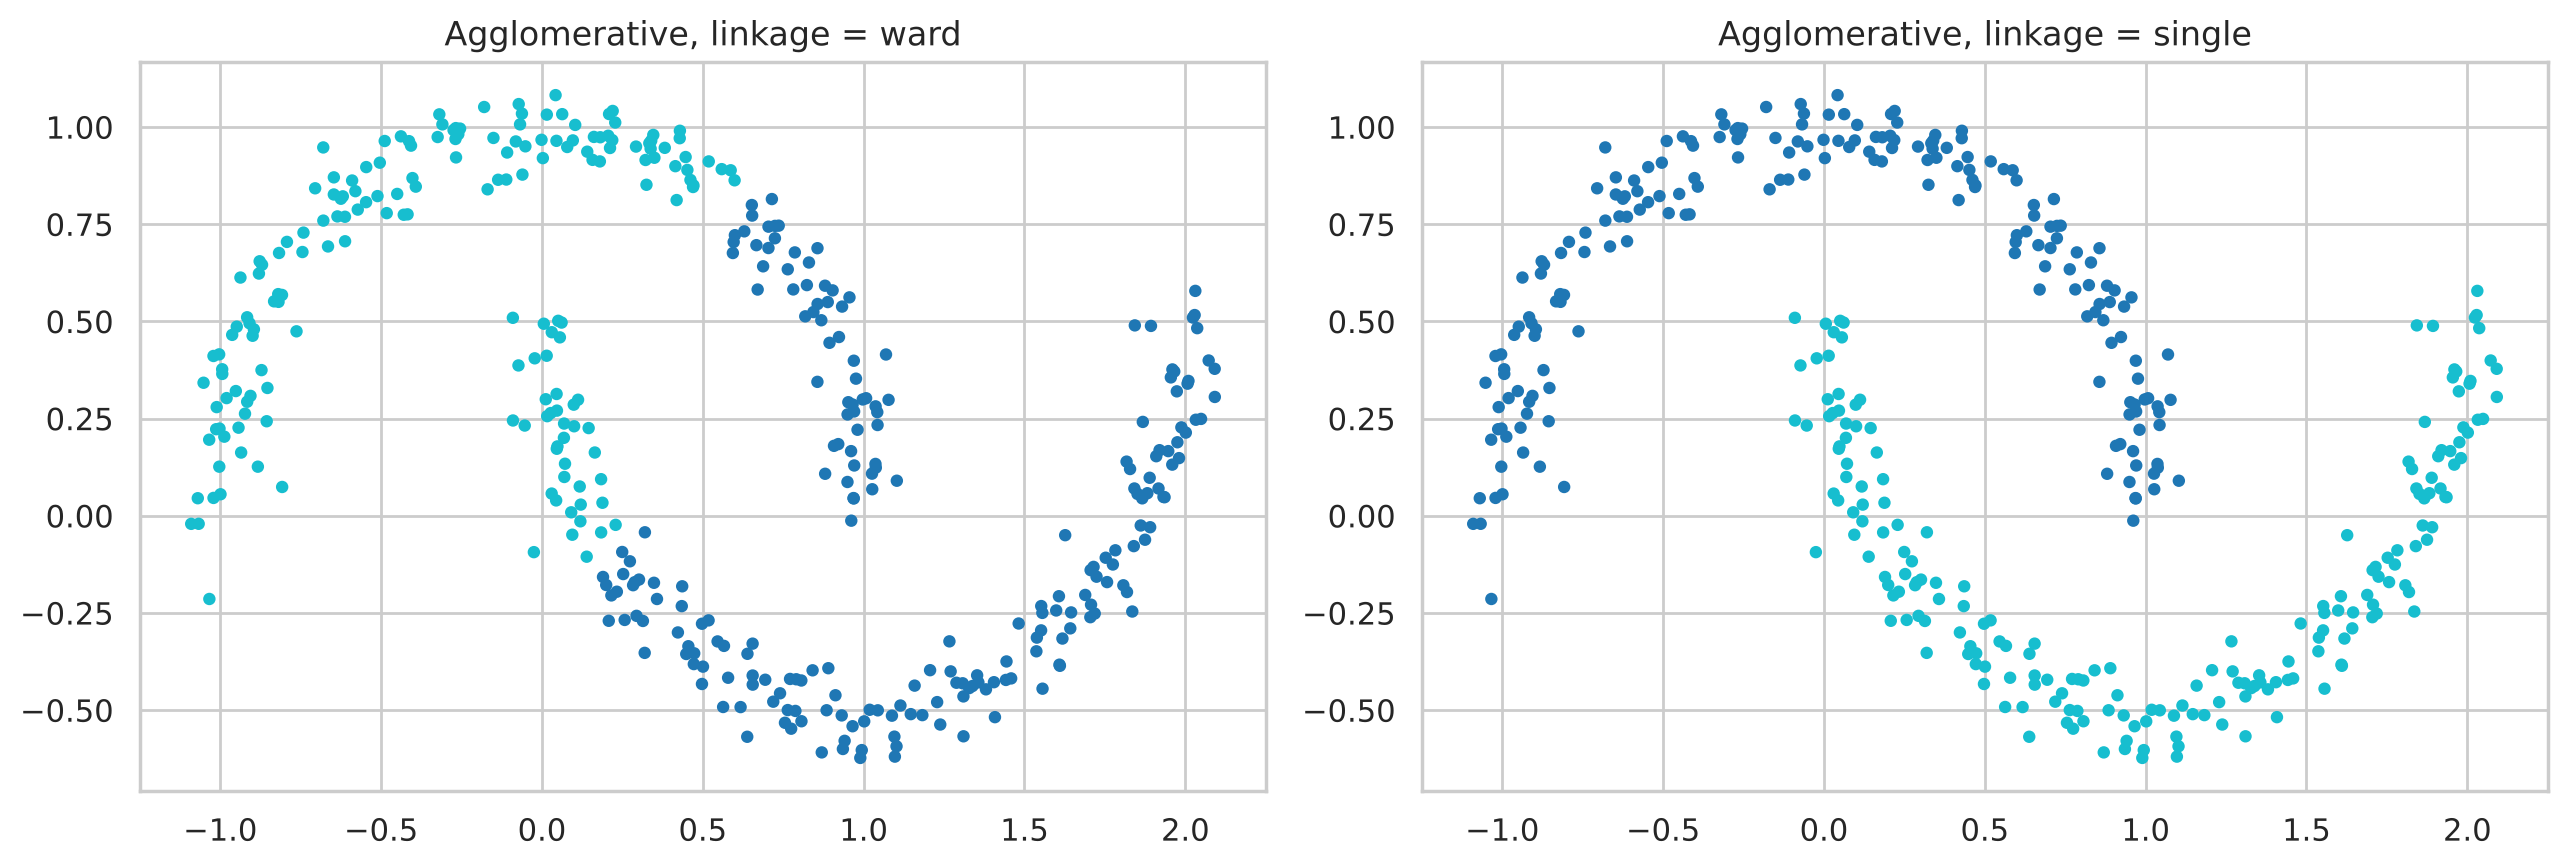

In [10]:
from sklearn.cluster import AgglomerativeClustering

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, link in zip(axes, ["ward", "single"]):
    labels = AgglomerativeClustering(n_clusters=2, linkage=link).fit_predict(X_moons)
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=labels, cmap="tab10", s=12)
    ax.set_title(f"Agglomerative, linkage = {link}")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

پیوند `single` می‌تواند خوشه‌های غیرکروی را تشخیص دهد، چون خوشه‌ها را مثل زنجیر به هم وصل می‌کند؛ ولی به نویز بسیار حساس است. عیب کلی خوشه‌بندی سلسله‌مراتبی: حافظه و زمان از مرتبهٔ $O(m^2)$ و بیشتر، پس برای دادهٔ بزرگ مناسب نیست.

## ۷. DBSCAN: خوشه‌بندی مبتنی بر چگالی

ایدهٔ **DBSCAN**: خوشه، ناحیه‌ای **پرچگال** از نقاط است که با ناحیه‌های کم‌چگال از بقیه جدا شده. دو ابرپارامتر دارد:
- `eps`: شعاع همسایگی
- `min_samples`: حداقل تعداد نقاط در همسایگی برای پرچگال بودن

هر نقطه یکی از این سه نوع است:
- **نقطهٔ هسته (Core):** حداقل `min_samples` همسایه در شعاع `eps` دارد.
- **نقطهٔ مرزی (Border):** همسایهٔ یک نقطهٔ هسته است، ولی خودش هسته نیست.
- **نویز (Noise):** هیچ‌کدام؛ برچسب $-1$ می‌گیرد.

مزایا: لازم نیست تعداد خوشه‌ها را بدانیم، خوشه‌هایی با **هر شکلی** را پیدا می‌کند و **دادهٔ پرت** را خودکار تشخیص می‌دهد.

</div>

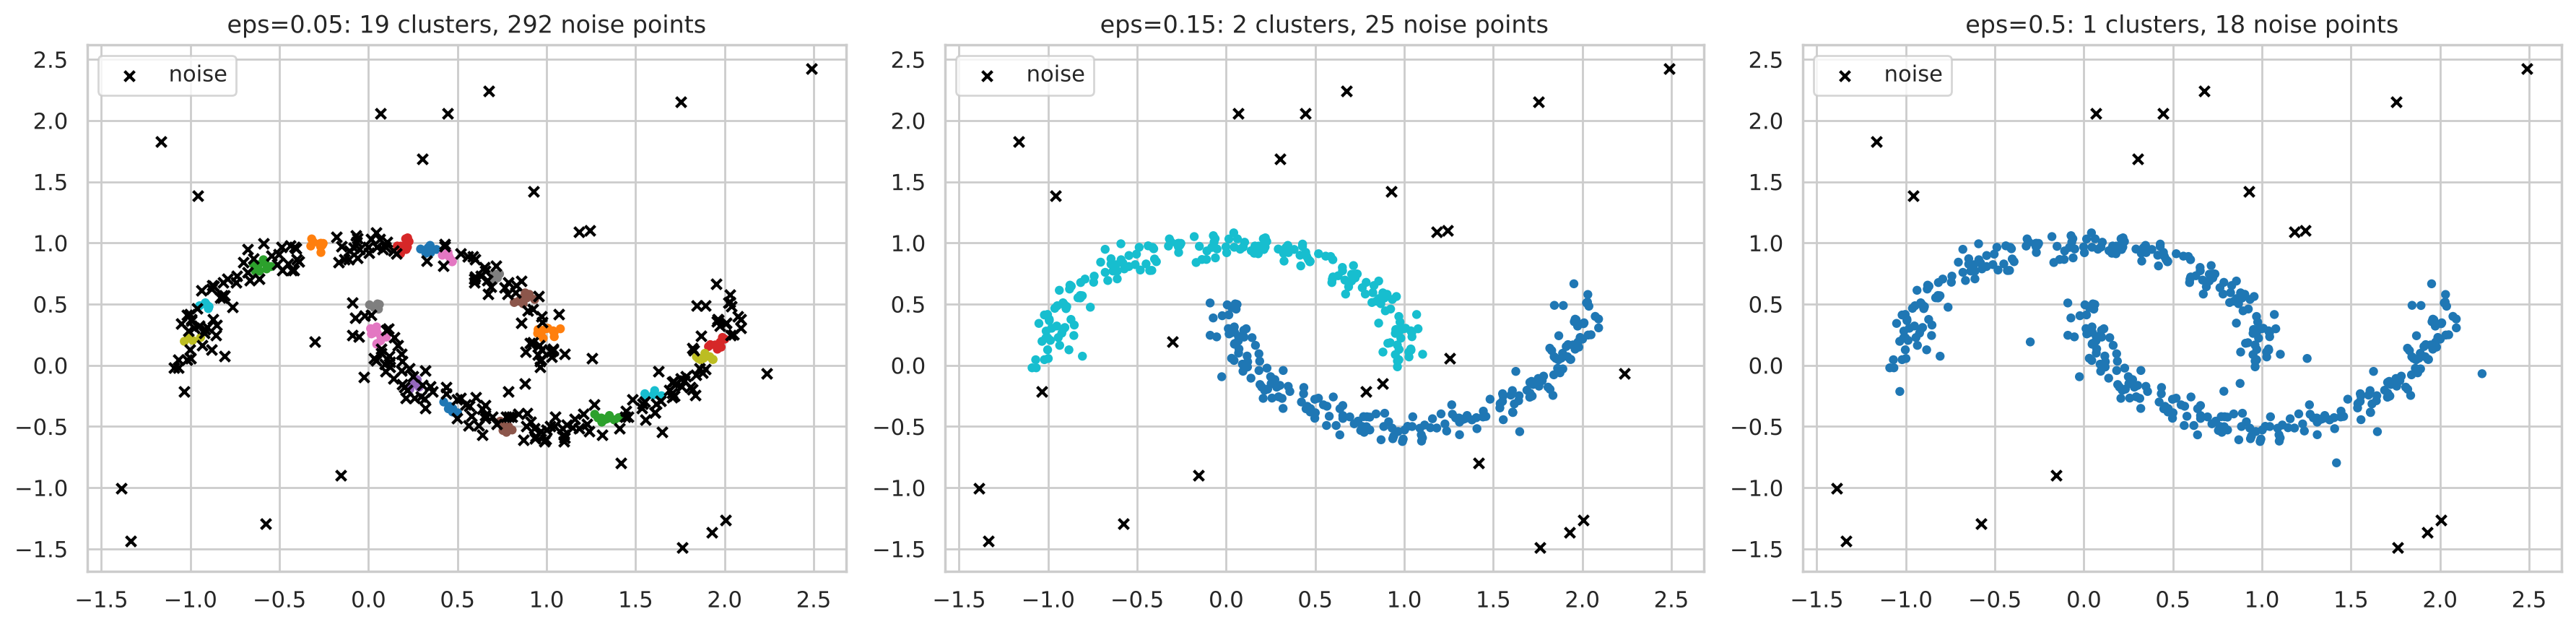

In [11]:
from sklearn.cluster import DBSCAN

X_noisy = np.vstack([X_moons, rng.uniform(-1.5, 2.5, (30, 2))])
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, eps in zip(axes, [0.05, 0.15, 0.5]):
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_noisy)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    ax.scatter(X_noisy[labels >= 0, 0], X_noisy[labels >= 0, 1], c=labels[labels >= 0], cmap="tab10", s=12)
    ax.scatter(X_noisy[labels == -1, 0], X_noisy[labels == -1, 1], c="black", marker="x", s=25, label="noise")
    ax.set_title(f"eps={eps}: {n_clusters} clusters, {np.sum(labels == -1)} noise points")
    ax.legend()
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- `eps` خیلی کوچک: بیشتر نقاط نویز تشخیص داده می‌شوند و خوشه‌ها تکه‌تکه می‌شوند.
- `eps` مناسب: دو ماه به‌خوبی جدا شده‌اند و نقاط تصادفی پراکنده، نویز تشخیص داده شده‌اند.
- `eps` خیلی بزرگ: همه چیز در یک خوشه ادغام می‌شود.

### انتخاب eps با نمودار فاصلهٔ k

برای هر نقطه، فاصله تا $k$-امین همسایهٔ نزدیکش را حساب می‌کنیم ($k$ برابر `min_samples`) و این فاصله‌ها را مرتب‌شده رسم می‌کنیم. جایی که نمودار ناگهان تند می‌شود («زانو»)، مقدار مناسبی برای `eps` است.

</div>

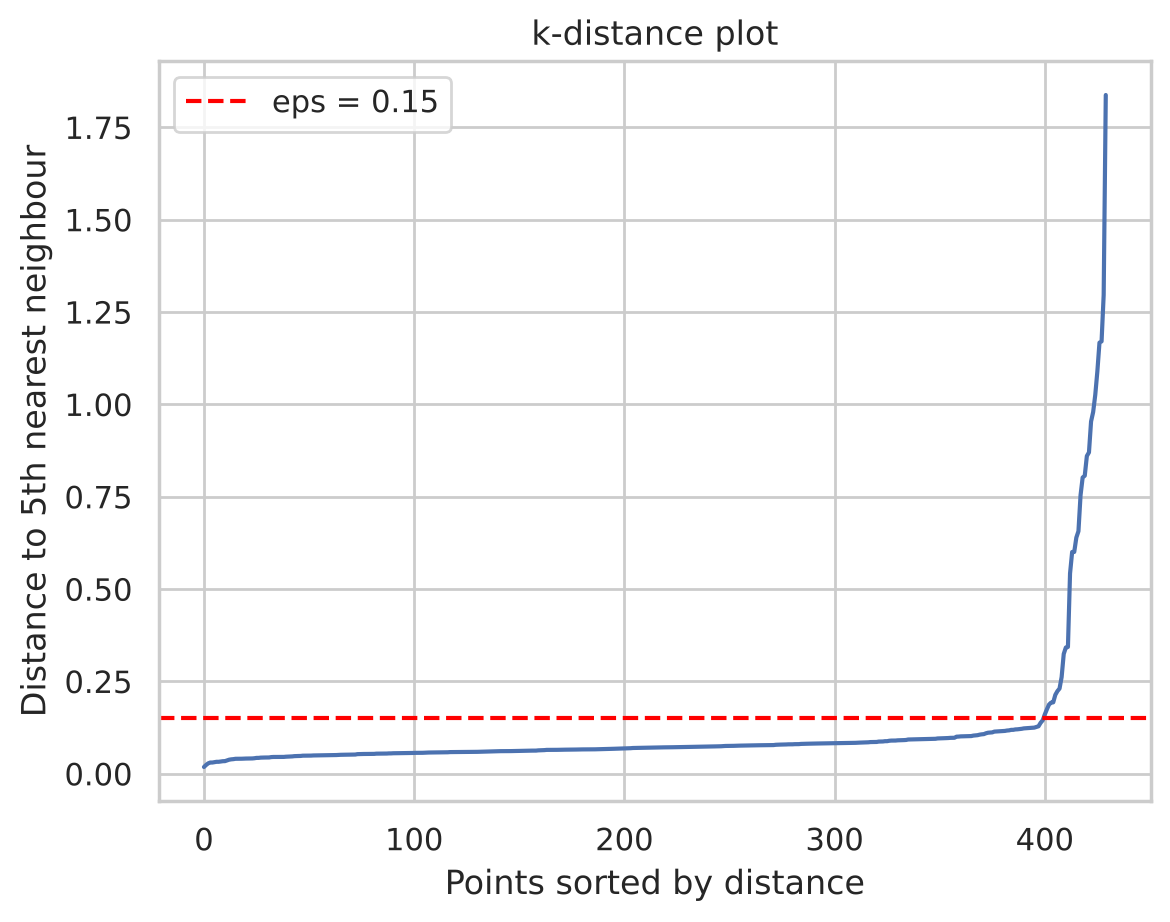

In [12]:
from sklearn.neighbors import NearestNeighbors

distances, _ = NearestNeighbors(n_neighbors=5).fit(X_noisy).kneighbors(X_noisy)
plt.plot(np.sort(distances[:, -1]))
plt.axhline(0.15, color="red", linestyle="--", label="eps = 0.15")
plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to 5th nearest neighbour")
plt.title("k-distance plot")
plt.legend()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**محدودیت DBSCAN:** وقتی خوشه‌ها **چگالی‌های بسیار متفاوت** دارند، یک `eps` برای همه مناسب نیست. الگوریتم **HDBSCAN** (در `sklearn.cluster`) این مشکل را حل می‌کند و فقط به `min_cluster_size` نیاز دارد.

## ۸. مدل مخلوط گوسی (GMM) و الگوریتم EM

**GMM** فرض می‌کند داده از ترکیب $K$ توزیع نرمال چندمتغیره تولید شده است. هر خوشه $k$ سه پارامتر دارد: میانگین $\boldsymbol{\mu}_k$، ماتریس کوواریانس $\Sigma_k$ (که شکل و جهت خوشه را تعیین می‌کند) و وزن $\pi_k$.

$$p(\mathbf{x}) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}\left(\mathbf{x} \mid \boldsymbol{\mu}_k, \Sigma_k\right)$$

تفاوت‌های مهم با K-Means:
- **خوشه‌بندی نرم:** به‌جای تخصیص قطعی، برای هر نقطه **احتمال** تعلق به هر خوشه را می‌دهد.
- **خوشه‌های بیضوی:** با کوواریانس کامل، خوشه‌های کشیده و چرخیده را هم مدل می‌کند.

### الگوریتم امید-بیشینه‌سازی (EM)

پارامترهای GMM با الگوریتم **EM** یاد گرفته می‌شوند؛ تعمیمی از همان ایدهٔ K-Means:

- **گام E (Expectation):** با پارامترهای فعلی، **مسئولیت** هر خوشه برای هر نقطه را حساب کن:

$$\gamma_{ik} = \frac{\pi_k \, \mathcal{N}\left(\mathbf{x}_i \mid \boldsymbol{\mu}_k, \Sigma_k\right)}{\sum_{j=1}^{K} \pi_j \, \mathcal{N}\left(\mathbf{x}_i \mid \boldsymbol{\mu}_j, \Sigma_j\right)}$$

- **گام M (Maximization):** پارامترها را با میانگین وزن‌دار، با وزن مسئولیت‌ها، به‌روز کن:

$$N_k = \sum_{i} \gamma_{ik} \qquad \boldsymbol{\mu}_k = \frac{1}{N_k}\sum_{i} \gamma_{ik}\, \mathbf{x}_i \qquad \Sigma_k = \frac{1}{N_k}\sum_{i} \gamma_{ik} \left(\mathbf{x}_i - \boldsymbol{\mu}_k\right)\left(\mathbf{x}_i - \boldsymbol{\mu}_k\right)^\top \qquad \pi_k = \frac{N_k}{m}$$

این دو گام تا همگرایی **لگاریتم درست‌نمایی** تکرار می‌شوند. هر تکرار EM تضمین می‌کند درست‌نمایی کاهش پیدا نکند.

</div>

In [13]:
from scipy.stats import multivariate_normal

def gmm_em(X, k, n_iter=100, tol=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    m, d = X.shape
    means = X[rng.choice(m, k, replace=False)]
    covs = np.array([np.cov(X, rowvar=False)] * k)
    weights = np.full(k, 1 / k)
    log_likelihoods = []

    for _ in range(n_iter):
        # E-step: responsibilities
        dens = np.column_stack([weights[j] * multivariate_normal(means[j], covs[j]).pdf(X) for j in range(k)])
        log_likelihoods.append(np.sum(np.log(dens.sum(axis=1))))
        resp = dens / dens.sum(axis=1, keepdims=True)

        # M-step: weighted parameter updates
        Nk = resp.sum(axis=0)
        means = (resp.T @ X) / Nk[:, None]
        for j in range(k):
            diff = X - means[j]
            covs[j] = (resp[:, j, None] * diff).T @ diff / Nk[j] + 1e-6 * np.eye(d)
        weights = Nk / m

        if len(log_likelihoods) > 1 and abs(log_likelihoods[-1] - log_likelihoods[-2]) < tol:
            break
    return resp.argmax(axis=1), means, covs, weights, log_likelihoods

em_labels, em_means, em_covs, em_weights, ll = gmm_em(X_aniso, k=3, seed=1)
print(f"Converged after {len(ll)} iterations, final log-likelihood = {ll[-1]:.1f}")

Converged after 27 iterations, final log-likelihood = -1258.8


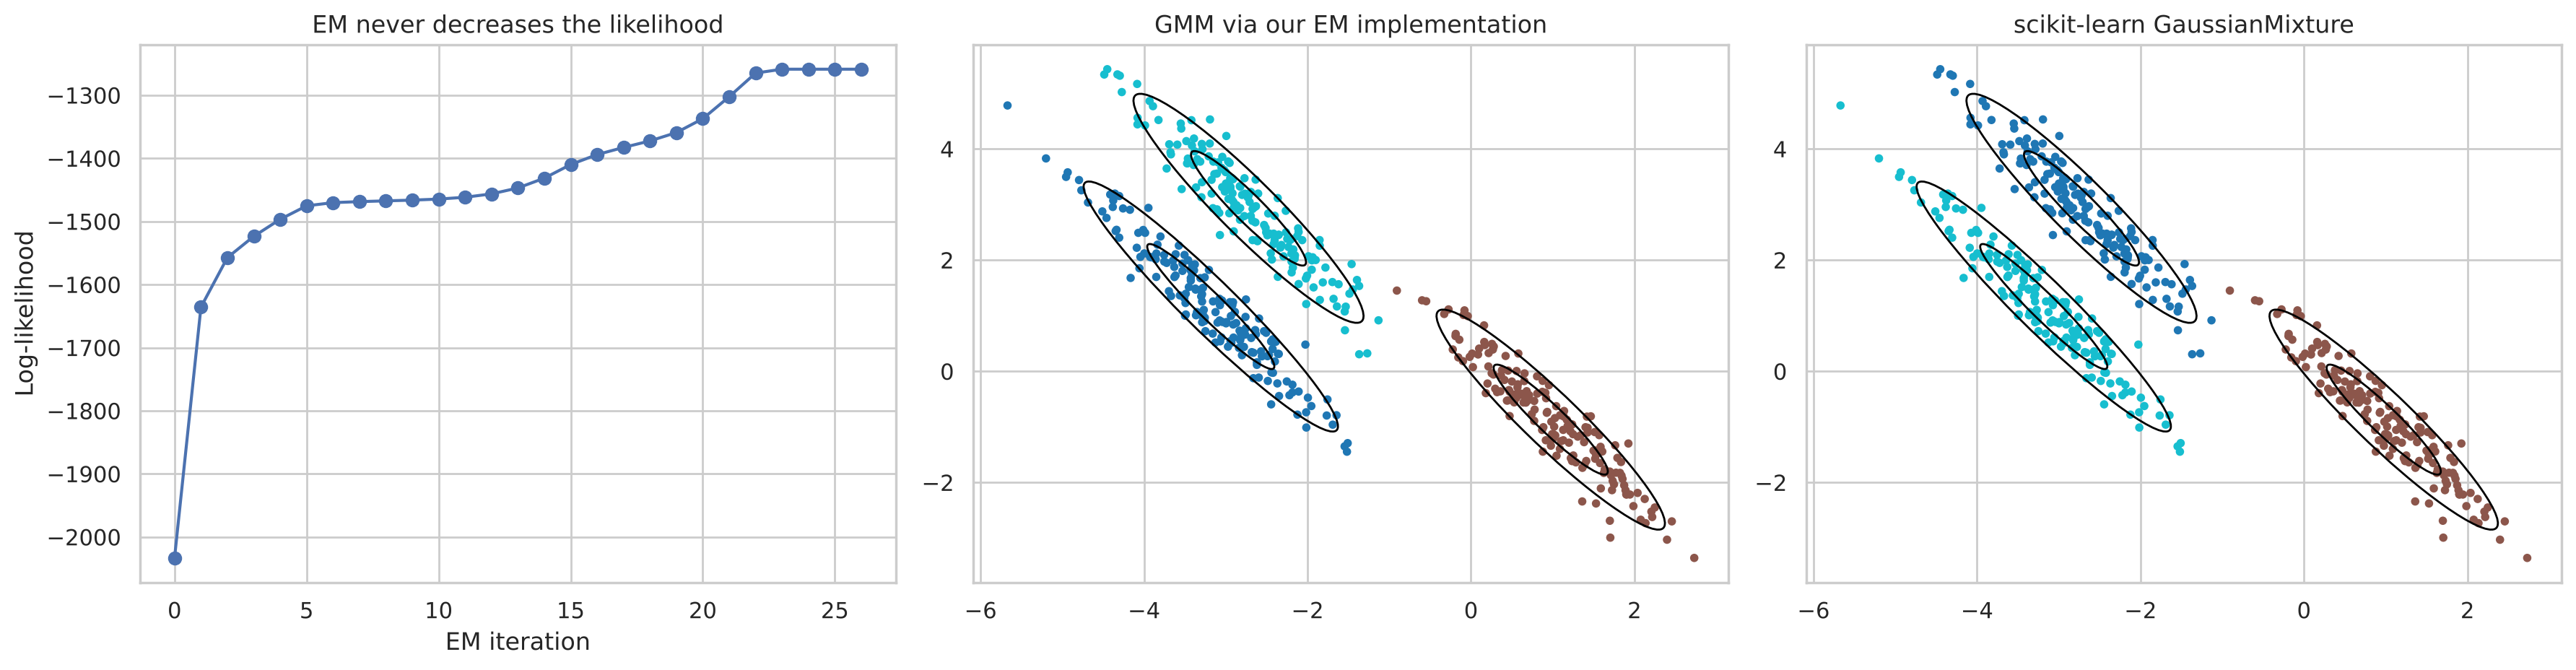

In [14]:
from sklearn.mixture import GaussianMixture
from matplotlib.patches import Ellipse

def draw_ellipse(mean, cov, ax, **kwargs):
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vecs[1, -1], vecs[0, -1]))
    for n_std in [1, 2]:
        w, h = 2 * n_std * np.sqrt(vals[::-1])
        ax.add_patch(Ellipse(mean, w, h, angle=angle, fill=False, **kwargs))

sk_gmm = GaussianMixture(n_components=3, covariance_type="full", random_state=42).fit(X_aniso)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].plot(ll, "o-")
axes[0].set_xlabel("EM iteration")
axes[0].set_ylabel("Log-likelihood")
axes[0].set_title("EM never decreases the likelihood")

axes[1].scatter(X_aniso[:, 0], X_aniso[:, 1], c=em_labels, cmap="tab10", s=10)
for j in range(3):
    draw_ellipse(em_means[j], em_covs[j], axes[1], color="black")
axes[1].set_title("GMM via our EM implementation")

axes[2].scatter(X_aniso[:, 0], X_aniso[:, 1], c=sk_gmm.predict(X_aniso), cmap="tab10", s=10)
for j in range(3):
    draw_ellipse(sk_gmm.means_[j], sk_gmm.covariances_[j], axes[2], color="black")
axes[2].set_title("scikit-learn GaussianMixture")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

برخلاف K-Means، GMM خوشه‌های کشیده را درست تشخیص می‌دهد و پیاده‌سازی ما با scikit-learn یکسان است. (EM هم مثل K-Means به مقداردهی اولیه حساس است و ممکن است در کمینهٔ محلی بماند؛ `GaussianMixture` با `n_init` چند شروع را امتحان می‌کند.)

### خوشه‌بندی نرم و انتخاب تعداد مؤلفه‌ها با BIC

</div>

Points with less than 90% confidence in their cluster: 0 of 500


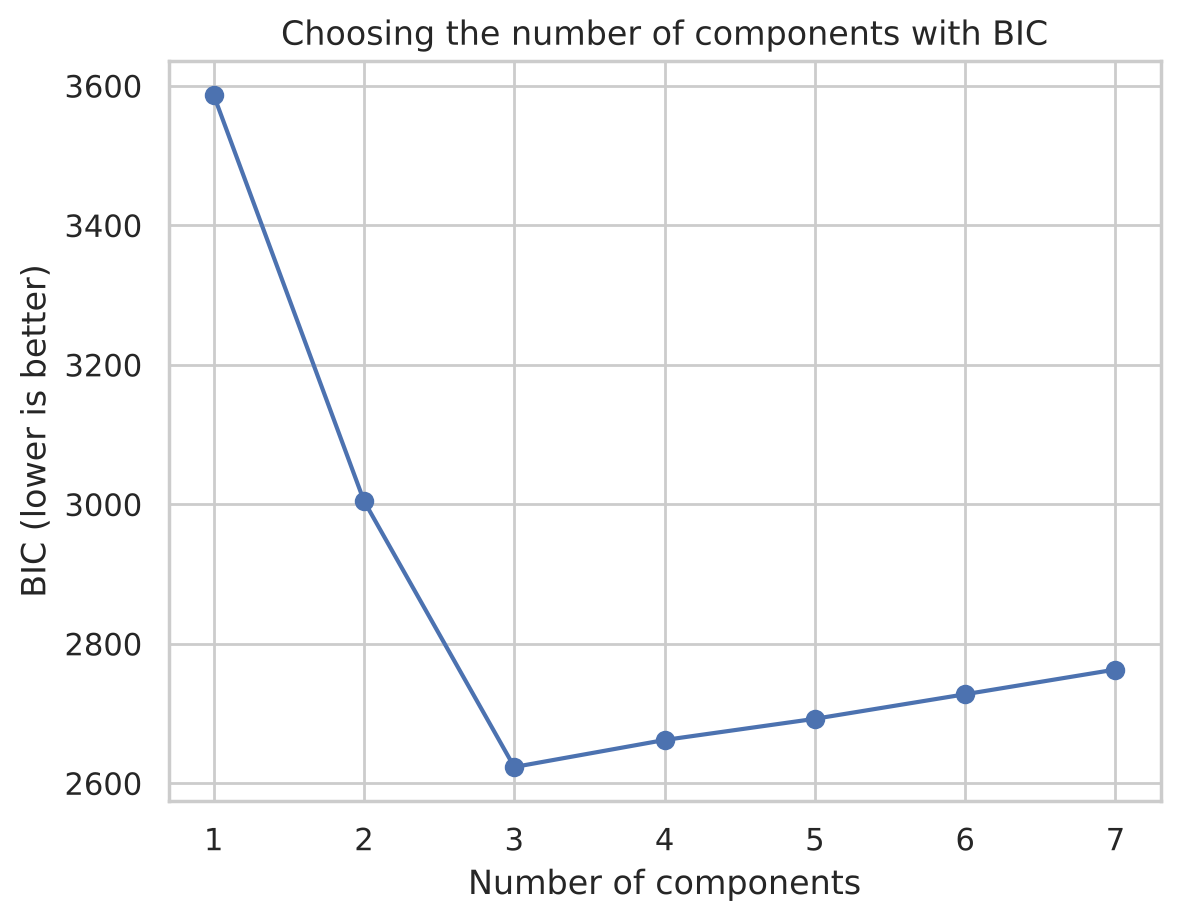

In [15]:
probs = sk_gmm.predict_proba(X_aniso)
uncertain = probs.max(axis=1) < 0.9
print(f"Points with less than 90% confidence in their cluster: {uncertain.sum()} of {len(X_aniso)}")

bic = [GaussianMixture(n_components=k, random_state=42).fit(X_aniso).bic(X_aniso) for k in range(1, 8)]
plt.plot(range(1, 8), bic, "o-")
plt.xlabel("Number of components")
plt.ylabel("BIC (lower is better)")
plt.title("Choosing the number of components with BIC")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**BIC (معیار اطلاعات بیزی)** درست‌نمایی را با جریمه‌ای برای تعداد پارامترها ترکیب می‌کند و کمینهٔ آن، تعداد مناسب مؤلفه‌ها را پیشنهاد می‌کند. اینجا BIC به‌درستی ۳ را انتخاب می‌کند.

## ۹. ارزیابی خوشه‌بندی وقتی برچسب واقعی داریم

گاهی (مثلاً برای مقایسهٔ الگوریتم‌ها روی دادهٔ محک) برچسب واقعی را داریم. **Adjusted Rand Index (ARI)** شباهت دو خوشه‌بندی را مستقل از شماره‌گذاری خوشه‌ها می‌سنجد: ۱ یعنی تطابق کامل و حدود صفر یعنی تصادفی.

</div>

In [16]:
from sklearn.metrics import adjusted_rand_score

y_aniso = make_blobs(n_samples=500, centers=3, random_state=170)[1]
results = {
    "K-Means": KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_aniso),
    "Agglomerative (ward)": AgglomerativeClustering(n_clusters=3).fit_predict(X_aniso),
    "DBSCAN": DBSCAN(eps=0.3, min_samples=10).fit_predict(X_aniso),
    "GMM": sk_gmm.predict(X_aniso),
}
pd.Series({name: adjusted_rand_score(y_aniso, labels) for name, labels in results.items()}, name="ARI").round(3)

K-Means                 0.564
Agglomerative (ward)    0.626
DBSCAN                  0.711
GMM                     1.000
Name: ARI, dtype: float64

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## جمع‌بندی

| الگوریتم | تعداد خوشه | شکل خوشه | نویز | مقیاس‌پذیری |
|---|---|---|---|---|
| K-Means | باید مشخص شود | کروی، اندازهٔ مشابه | ندارد | عالی |
| سلسله‌مراتبی | از دندروگرام | بسته به linkage | ندارد | ضعیف |
| DBSCAN / HDBSCAN | خودکار | دلخواه | **تشخیص می‌دهد** | خوب |
| GMM | باید مشخص شود (BIC) | بیضوی | ندارد | متوسط |

- همیشه قبل از خوشه‌بندی مبتنی بر فاصله، **مقیاس‌بندی** کنید.
- Inertia، Silhouette و BIC راهنما هستند، نه حکم نهایی؛ **تفسیر خوشه‌ها** مهم‌ترین بخش کار است.
- الگوریتم را بر اساس شکل مورد انتظار خوشه‌ها و وجود نویز انتخاب کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. بخش‌بندی مشتریان را با سه ویژگی `Age`، `Income` و `Spending` تکرار کنید. بهترین $K$ تغییر می‌کند؟ بخش‌های جدید را تفسیر کنید.

۲. نمودار Silhouette هر نمونه را برای $K=5$ رسم کنید (`silhouette_samples`). کدام خوشه ضعیف‌تر است؟

۳. `HDBSCAN` را روی `X_noisy` اجرا کنید و با DBSCAN مقایسه کنید.

۴. **فشرده‌سازی تصویر:** تصویر رنگی `load_sample_image("china.jpg")` را بارگذاری کنید، پیکسل‌ها را با K-Means به ۸ رنگ خوشه‌بندی کنید و هر پیکسل را با رنگ مرکز خوشه‌اش جایگزین کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** بخش‌بندی مشتریان را با سه ویژگی `Age`، `Income` و `Spending` تکرار کنید. بهترین $K$ تغییر می‌کند؟ بخش‌های جدید را تفسیر کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** نمودار Silhouette هر نمونه را برای $K=5$ رسم کنید (`silhouette_samples`). کدام خوشه ضعیف‌تر است؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** `HDBSCAN` را روی `X_noisy` اجرا کنید و با DBSCAN مقایسه کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** **فشرده‌سازی تصویر:** تصویر رنگی `load_sample_image("china.jpg")` را بارگذاری کنید، پیکسل‌ها را با K-Means به ۸ رنگ خوشه‌بندی کنید و هر پیکسل را با رنگ مرکز خوشه‌اش جایگزین کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید
